# Yankees Championship Seasons: Regular Season Batting Statistics

**Name:** James Gilby
**Date:** November 1, 2026

## Introduction

For this project, I collected batting statistics from Wikipedia
for the Yankees' 1996, 1998, 1999, 2000, and 2009 seasons.
I chose these seasons because the Yankees won the World Series
in each of these years. It is also the most recent winning years of the teams league leading, 27 World Series Championships.

I used hits, home runs, and RBIs to compare
player performance across these seasons. After collecting and
cleaning the data, I answered five questions using pandas
and created graphs using Seaborn.

I used requests and BeautifulSoup to collect the data,
pandas to organize and analyze it, and Seaborn and Matplotlib
to create the graphs.

In [1]:
# Import libraries for web scraping
import requests
from bs4 import BeautifulSoup as bs

# Import libraries for analysis and graphs
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# Start with 1996 to see how the batting tables are organized
url = "https://en.wikipedia.org/wiki/1996_New_York_Yankees_season"
# Add a user agent so wikipedia accepts the request
headers = {
    "User-Agent": "GilbyYankeesProject/1.0 (https://github.com/jgilbs44)"
}

response = requests.get(url, headers=headers)

# Check that the page loaded
status = response.status_code

if status == 200:
    page = response.text
    soup = bs(page, "html.parser")
    print("Page loaded successfully.")
else:
    print(f"Oops! Received status code {status}")

Page loaded successfully.


## Locating Batting Tables

I checked the table headings to identify the tables
with player names, hits, home runs, and RBIs.

In [3]:
# Finding tables on the page
tables = soup.find_all("table", class_="wikitable")


batting_tables = []

for table in tables:
    first_row = table.find("tr")
    headings = first_row.get_text(" ", strip=True)

    # Keep tables containing home runs and RBIs
    if "HR" in headings and "RBI" in headings:
        batting_tables.append(table)
        print(headings)

Pos Player G AB H Avg. HR RBI
Player G AB H Avg. HR RBI


## Starting Batters

I checked one player's row, then collected the starting
batters' names, hits, home runs, and RBIs. I organized
the data in a pandas DataFrame and labeled the season as 1996.

In [4]:
# Check the first batting table and one player row
first_table = batting_tables[0]
rows = first_table.find_all("tr")

print(rows[1].get_text(" ", strip=True))

C Joe Girardi 124 422 124 .294 2 45


In [5]:
# Collect the 1996 starters from the first table
player_data = []

for row in rows[1:]:
    cells = row.find_all(["th", "td"])

    player = cells[1].get_text(strip=True)
    hits = cells[4].get_text(strip=True)
    home_runs = cells[6].get_text(strip=True)
    rbis = cells[7].get_text(strip=True)

    player_data.append([1996, player, hits, home_runs, rbis])

yankees_1996 = pd.DataFrame(
    player_data,
    columns=["Season", "Player", "H", "HR", "RBI"]
)

yankees_1996

,Season,Player,H,HR,RBI
0,1996,Joe Girardi,124,2,45
1,1996,Tino Martinez,174,25,117
2,1996,Mariano Duncan,136,8,56
3,1996,Wade Boggs,156,2,41
4,1996,Derek Jeter,183,10,78
5,1996,Tim Raines,57,9,33
6,1996,Bernie Williams,168,29,102
7,1996,Paul O'Neill,165,19,91
8,1996,Rubén Sierra,93,11,52


### Organizing the 1996 Starting Batters

I looped through the rows in the first batting table. Using
`rows[1:]` skips the heading row so I only collect player records.

For each row, I collected the table cells and extracted the player's
name, hits (H), home runs (HR), and runs batted in (RBI). The numbers
inside `cells[...]` refer to each column's position, starting from
zero. These positions match the headings checked earlier.
`get_text(strip=True)` extracts the text and removes surrounding
whitespace.

I stored each player's statistics in the `player_data` list
and included 1996 as the season. Then I converted that list into
a pandas DataFrame named `yankees_1996`, with one row per starting
batter and labeled columns for the season, player, and statistics.

## Other Batters

I collected the same statistics from the second batting
table and combined them with the starting batters. This placed
the players from both 1996 batting tables into one DataFrame.

In [6]:
# Collect the other 1996 batters from the second table
other_rows = batting_tables[1].find_all("tr")
other_player_data = []

for row in other_rows[1:]:
    cells = row.find_all(["th", "td"])

    player = cells[0].get_text(strip=True)
    hits = cells[3].get_text(strip=True)
    home_runs = cells[5].get_text(strip=True)
    rbis = cells[6].get_text(strip=True)

    other_player_data.append([1996, player, hits, home_runs, rbis])

# Combine both groups into the 1996 DataFrame
yankees_1996 = pd.DataFrame(
    player_data + other_player_data,
    columns=["Season", "Player", "H", "HR", "RBI"]
)

yankees_1996

,Season,Player,H,HR,RBI
0,1996,Joe Girardi,124,2,45
1,1996,Tino Martinez,174,25,117
2,1996,Mariano Duncan,136,8,56
3,1996,Wade Boggs,156,2,41
4,1996,Derek Jeter,183,10,78
5,1996,Tim Raines,57,9,33
6,1996,Bernie Williams,168,29,102
7,1996,Paul O'Neill,165,19,91
8,1996,Rubén Sierra,93,11,52
9,1996,Jim Leyritz,70,7,40


## Loading All Five Seasons

I requested the Wikipedia pages for 1996, 1998, 1999,
2000, and 2009 and stored each page under its season.

In [7]:
seasons = [1996, 1998, 1999, 2000, 2009]

# Request and save each season's page
season_pages = {}

for season in seasons:
    url = f"https://en.wikipedia.org/wiki/{season}_New_York_Yankees_season"
    response = requests.get(url, headers=headers)
    status = response.status_code

    if status == 200:
        season_pages[season] = bs(response.text, "html.parser")
        print(f"{season}: Page loaded successfully.")
    else:
        print(f"{season}: Received status code {status}")

1996: Page loaded successfully.
1998: Page loaded successfully.
1999: Page loaded successfully.
2000: Page loaded successfully.
2009: Page loaded successfully.


## Locating Batting Tables for All Seasons

I found each season's batting tables by checking for
HR and RBI in the headings. I also displayed the headings
to check the column order.

In [8]:
# Find the batting tables for each season
all_batting_tables = {}

for season in seasons:
    season_soup = season_pages[season]
    tables = season_soup.find_all("table", class_="wikitable")
    all_batting_tables[season] = []

    for table in tables:
        first_row = table.find("tr")
        headings = first_row.get_text(" ", strip=True)

        if "HR" in headings and "RBI" in headings:
            all_batting_tables[season].append(table)
            print(season, headings)

1996 Pos Player G AB H Avg. HR RBI
1996 Player G AB H Avg. HR RBI
1998 Pos Player G AB H Avg. HR RBI
1998 Player G AB H Avg. HR RBI
1999 Pos Player G AB H Avg. HR RBI
1999 Player G AB H Avg. HR RBI
2000 Pos Player G AB R H HR RBI Avg. SB
2000 Player G AB R H HR RBI Avg. SB
2009 Player G AB R H 2B 3B HR RBI BB AVG SB


## Combining the Five Seasons

I collected player names, hits, home runs, and RBIs from
each season's batting tables. Since the column order varied,
I used the headings to find the correct columns.

In [9]:
# Collect player statistics from all five seasons
all_player_data = []

for season in seasons:
    for table in all_batting_tables[season]:
        rows = table.find_all("tr")

       
        column_names = []
        for cell in rows[0].find_all(["th", "td"]):
            column_names.append(cell.get_text(strip=True))

        # Find the columns by name because their order changes between seasons
        player_col = column_names.index("Player")
        hits_col = column_names.index("H")
        hr_col = column_names.index("HR")
        rbi_col = column_names.index("RBI")

        # Only use rows that match the table headings
        for row in rows[1:]:
            cells = row.find_all(["th", "td"])

            if len(cells) == len(column_names):
                player = cells[player_col].get_text(strip=True)
                hits = cells[hits_col].get_text(strip=True)
                home_runs = cells[hr_col].get_text(strip=True)
                rbis = cells[rbi_col].get_text(strip=True)

                all_player_data.append(
                    [season, player, hits, home_runs, rbis]
                )
           

yankees = pd.DataFrame(
    all_player_data,
    columns=["Season", "Player", "H", "HR", "RBI"]
)

# Count the rows collected for each season
yankees.groupby("Season").size()

Season
1996    25
1998    19
1999    21
2000    24
2009    24
dtype: int64

## Cleaning the Data

I checked for summary rows, missing values, and duplicate records.
I also made sure hits, home runs, and RBIs were stored as numbers
so they could be used in calculations.

In [10]:
# Check the bottom rows for totals
yankees.tail()

,Season,Player,H,HR,RBI
108,2009,Alex Rodriguez,127,30,100
109,2009,Nick Swisher,124,29,82
110,2009,Mark Teixeira,178,39,122
111,2009,Pitcher totals,3,0,3
112,2009,Team totals,1604,244,831


I removed the Team totals and Pitcher totals rows and analyzed
the individual players listed in the tables. This excluded the
2009 pitcher summary's 3 hits and 3 RBIs.

In [11]:
# Remove summary rows
yankees = yankees[yankees["Player"] != "Team totals"]
yankees = yankees[yankees["Player"] != "Pitcher totals"].copy()

# Change the scraped stats from text to numbers so I can add them
for column in ["H", "HR", "RBI"]:
    yankees[column] = pd.to_numeric(yankees[column])

# Check for missing values and repeated player season records
print("Missing values:")
print(yankees.isna().sum())

print("Duplicate player-season rows:")
print(yankees.duplicated(subset=["Season", "Player"]).sum())

# Count the remaining player rows in each season
yankees.groupby("Season").size()

Missing values:
Season    0
Player    0
H         0
HR        0
RBI       0
dtype: int64
Duplicate player-season rows:
0


Season
1996    25
1998    19
1999    21
2000    24
2009    22
dtype: int64

After removing the summary rows, the dataset contains 111
player season records with no missing values or duplicate
player season records.

## Question 1: How do the players' combined home runs compare across the five seasons?

I added the individual players' home runs for each season
and compared the totals.

In [12]:
# Add the players' home runs for each season
home_runs_by_season = yankees.groupby("Season", as_index=False)["HR"].sum()

home_runs_by_season

,Season,HR
0,1996,162
1,1998,207
2,1999,195
3,2000,205
4,2009,244


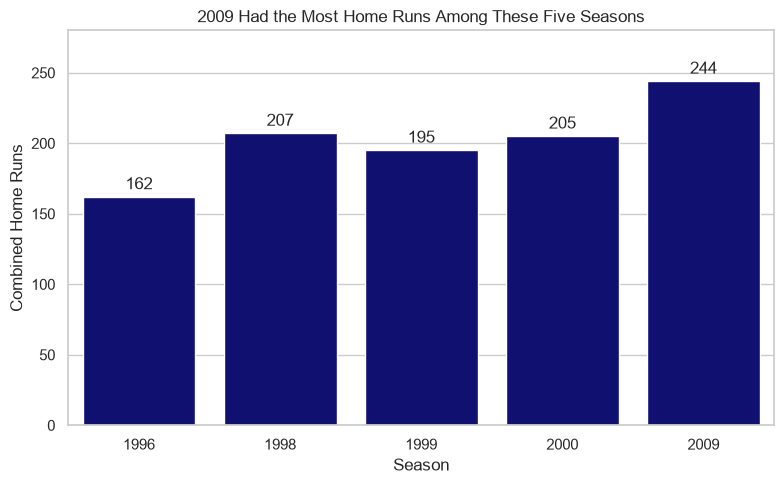

In [13]:
# Create the home run graph and label each bar
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=home_runs_by_season,
    x="Season",
    y="HR",
    color="navy"
)

ax.bar_label(ax.containers[0], padding=3)


plt.title("2009 Had the Most Home Runs Among These Five Seasons")
plt.xlabel("Season")
plt.ylabel("Combined Home Runs")
plt.ylim(0, 280)

plt.tight_layout()
plt.show()

Among the five seasons analyzed, 2009 had the most combined
home runs with 244, while 1996 had the fewest with 162.
The other three seasons were closer together, ranging from
195 to 207 home runs.

## Question 2: How do the players' combined RBIs compare across the five seasons?

I added the runs batted in (RBIs) for the individual players
listed in each season's batting tables and compared the totals.

In [14]:
# Add the players' RBIs for each season
rbis_by_season = yankees.groupby("Season", as_index=False)["RBI"].sum()


rbis_by_season

,Season,RBI
0,1996,830
1,1998,906
2,1999,854
3,2000,833
4,2009,878


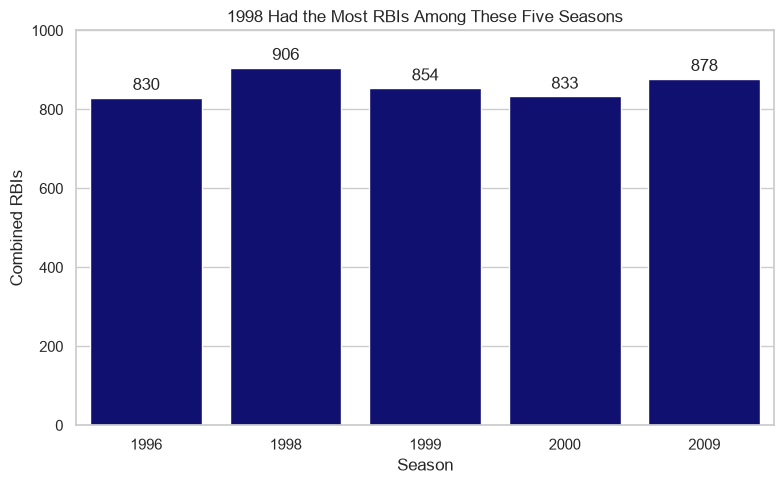

In [15]:
# Create the RBI graph and label each bar
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=rbis_by_season,
    x="Season",
    y="RBI",
    color="navy"
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("1998 Had the Most RBIs Among These Five Seasons")
plt.xlabel("Season")
plt.ylabel("Combined RBIs")
plt.ylim(0, 1000)

plt.tight_layout()
plt.show()

Based on the individual batting records collected, 1998 had
the most combined RBIs with 906, followed by 2009 with 878.
The 1996 season had the fewest with 830. Although 2009 led
these five seasons in home runs, 1998 led in RBIs.

## Question 3: How many players hit at least 20 home runs each season?

I selected the players who hit 20 or more home runs, then
counted how many qualified in each season.

In [16]:
# Count the players with at least 20 home runs in each season
players_20_hr = yankees[yankees["HR"] >= 20]


counts_20_hr = players_20_hr.groupby("Season").size()


counts_20_hr

Season
1996    2
1998    4
1999    3
2000    3
2009    7
dtype: int64

## Results
The 2009 season had the most players with at least 20 home runs,
with seven. The 1996 season had the fewest, with two. There were
four in 1998 and three each in 1999 and 2000.

## Question 4: What percentage of each season's home runs came from its top three home run hitters?

For each season, I selected the three players with the most
home runs and added their totals. I divided that sum by the
combined home runs for all listed players and multiplied by 100
to calculate the percentage.

In [17]:
# Calculate the top three hitters' share for each season
top_three_results = []

for season in seasons:
    
    season_data = yankees[yankees["Season"] == season]

    # Sort home runs from highest to lowest and select three players
    sorted_players = season_data.sort_values("HR", ascending=False)
    top_three = sorted_players.head(3)

    # Find what percentage of the season total came from the top three
    top_three_hr = top_three["HR"].sum()
    total_hr = season_data["HR"].sum()
    percentage = (top_three_hr / total_hr) * 100

    top_three_results.append(
        [season, top_three_hr, total_hr, round(percentage, 2)]
    )

# Organize the results into a DataFrame
top_three_share = pd.DataFrame(
    top_three_results,
    columns=["Season", "Top Three HR", "Total HR", "Percentage"]
)

top_three_share

,Season,Top Three HR,Total HR,Percentage
0,1996,73,162,45.06
1,1998,78,207,37.68
2,1999,78,195,40.00
3,2000,78,205,38.05
4,2009,98,244,40.16


The top three home run hitters accounted for the largest share
in 1996, at 45.06%, and the smallest share in 1998, at 37.68%.
In all five seasons, the top three hitters contributed less
than half of the combined home runs.

## Question 5: Which five players had the most combined hits across these five seasons?

I grouped the records by player and added each player's hits
across the five selected seasons. Then I sorted the totals
from highest to lowest and displayed the top five players.

In [18]:
# Add each player's hits and find the five highest totals
hits_by_player = yankees.groupby("Player", as_index=False)["H"].sum()

hits_by_player = hits_by_player.sort_values("H", ascending=False)

top_five_hits = hits_by_player.head(5)
top_five_hits

,Player,H
17,Derek Jeter,1018
3,Bernie Williams,704
51,Paul O'Neill,686
65,Tino Martinez,625
10,Chuck Knoblauch,449


Derek Jeter had the most combined hits with 1,018, followed by
Bernie Williams with 704, Paul O'Neill with 686, Tino Martinez
with 625, and Chuck Knoblauch with 449.

These totals only cover the five selected seasons. Players who
appeared in more of those seasons had more opportunities to
accumulate hits, which should be considered when comparing them.

## Conclusion

Among the five seasons analyzed, 2009 had the most combined
home runs with 244 and the most players reaching 20 home runs,
with seven. However, 1998 had the highest combined RBI total
with 906.

The top three home run hitters contributed the largest share
in 1996 at 45.06%, compared with the smallest share in 1998 at
37.68%. Their contribution was less than half of the combined
home runs in every season.

These results describe the individual player records collected
from the Wikipedia batting tables. Summary rows were excluded,
including the 2009 pitcher totals, so the calculations do not
include those pitchers' batting contributions.